In [902]:

from google.colab import files

uploaded = files.upload()

import pandas as pd

df = pd.read_csv("Nassau Candy Distributor.csv")
print(df.head())



Saving Nassau Candy Distributor.csv to Nassau Candy Distributor (15).csv
   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code   Division    Region     Product ID  \
0 

In [903]:
!pkill -f "streamlit run app.py" || true

^C


In [904]:
!streamlit run app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false > /content/streamlit2.log 2>&1 &

In [905]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [906]:
from google.colab import files
files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [907]:
import os

for file in ["app.py", "profit_prediction_model.pkl",
             "Nassau Candy Distributor.csv"]:
    print(file, "->", os.path.exists("/content/" + file))

app.py -> True
profit_prediction_model.pkl -> True
Nassau Candy Distributor.csv -> True


In [908]:
import os

print("Project files:")
for file in os.listdir("/content"):
    if file.endswith((".py", ".csv", ".pkl", ".ipynb", ".md", ".txt")):
        print(file)

Project files:
Nassau Candy Distributor (7).csv
Nassau Candy Distributor (6).csv
Nassau Candy Distributor (2).csv
Nassau Candy Distributor (3).csv
Nassau Candy Distributor (13).csv
app.py
Nassau Candy Distributor (12).csv
Nassau Candy Distributor (5).csv
Nassau Candy Distributor (14).csv
Nassau Candy Distributor (4).csv
Nassau Candy Distributor (11).csv
Nassau Candy Distributor (10).csv
Nassau Candy Distributor (15).csv
Nassau Candy Distributor (8).csv
profit_prediction_model.pkl
Nassau Candy Distributor.csv
Nassau Candy Distributor (1).csv
Nassau Candy Distributor (9).csv


In [909]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [910]:
!cat /content/streamlit2.log

In [911]:
!ps aux | grep '[s]treamlit run'

root       15983  1.2  1.7 2495016 231952 ?      Rl   10:28   0:13 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false
root       15997  0.7  0.5 443484 72232 ?        R    10:28   0:07 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8501 --server.address 0.0.0.0
root       20552 71.0  0.2  44668 33960 ?        R    10:46   0:00 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false


In [912]:
from google.colab import output
output.serve_kernel_port_as_window(8502)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [913]:
!cat /content/streamlit2.log

In [914]:
!streamlit run app.py --server.port 8502 --server.address 0.0.0.0 > /content/streamlit2.log 2>&1 &

In [915]:
!cat /content/streamlit.log



2026-10-13 10:28:15.113 Port 8501 is not available
.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.107.211.230:8501

  Stopping...


In [916]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [917]:
!cat /content/streamlit.log

In [918]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [919]:
import os
print(os.path.exists("app.py"))

True


In [920]:
%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Nassau Candy Profitability",
    layout="wide"
)

st.title("Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance")

df = pd.read_csv("Nassau Candy Distributor.csv")

total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_cost = df["Cost"].sum()
margin = total_profit / total_sales * 100 if total_sales else 0

c1, c2, c3, c4 = st.columns(4)

c1.metric("Total Sales", f"${total_sales:,.2f}")
c2.metric("Gross Profit", f"${total_profit:,.2f}")
c3.metric("Total Cost", f"${total_cost:,.2f}")
c4.metric("Profit Margin", f"{margin:.2f}%")

df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

monthly = (
    df.dropna(subset=["Order Date"])
    .assign(Month=lambda x: x["Order Date"].dt.to_period("M").astype(str))
    .groupby("Month")[["Sales", "Gross Profit"]]
    .sum()
)

st.subheader("Monthly Sales and Gross Profit")
st.line_chart(monthly)

st.subheader("Top 10 Products by Gross Profit")
products = (
    df.groupby("Product Name")["Gross Profit"]
    .sum()
    .nlargest(10)
    .sort_values()
)
st.bar_chart(products)

Overwriting app.py


In [921]:
!cat /content/streamlit.log

In [922]:
import os

print("Dataset available:", os.path.exists("Nassau Candy Distributor.csv"))
print("Model available:", os.path.exists("profit_prediction_model.pkl"))

Dataset available: True
Model available: True


In [923]:
!pip install streamlit

In [924]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

Mean Absolute Error: 0.007807405590988188
R² Score: 0.999528521556322


In [925]:
import joblib

joblib.dump(model, "profit_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [926]:
print("MAE:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

print("\nActual vs Predicted Sample:")
comparison = pd.DataFrame({
    "Actual Gross Profit": y_test.iloc[:10].values,
    "Predicted Gross Profit": predictions[:10]
})

display(comparison)

MAE: 0.007807405590988188
R2 Score: 0.999528521556322

Actual vs Predicted Sample:


,Actual Gross Profit,Predicted Gross Profit
0,7.20,7.20
1,2.45,2.45
2,7.35,7.35
3,9.60,9.60
4,7.50,7.50
5,19.20,19.20
6,21.60,21.60
7,7.50,7.50
8,4.98,4.98
9,4.80,4.80


In [927]:
product_data = df.groupby(
    ["Product ID", "Product Name"], as_index=False
).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
})

product_data["Profit Margin (%)"] = (
    product_data["Gross Profit"] /
    product_data["Sales"].replace(0, float("nan")) * 100
)

low_margin = product_data[
    product_data["Sales"] > 0
].sort_values("Profit Margin (%)").head(10)

print("10 Lowest-Margin Products")
print(low_margin.to_string(index=False))

10 Lowest-Margin Products
   Product ID                      Product Name    Sales  Gross Profit    Cost  Units  Profit Margin (%)
OTH-KAZ-38000                         Kazookles  1205.75         92.75 1113.00    371           7.692308
SUG-FUN-75000                           Fun Dip    12.00          4.80    7.20      8          40.000000
SUG-NER-92000                             Nerds    15.00          7.00    8.00     10          46.666667
SUG-SWE-91000                         SweeTARTS    61.50         28.70   32.80     41          46.666667
OTH-LIC-15000                Lickable Wallpaper  7860.00       3930.00 3930.00    393          50.000000
OTH-GUM-21000                         Wonka Gum   597.50        310.70  286.80    478          52.000000
OTH-FIZ-56000              Fizzy Lifting Drinks    78.75         47.25   31.50     21          60.000000
SUG-LAF-25000                       Laffy Taffy    53.73         33.48   20.25     27          62.311558
CHO-MIL-31000        Wonka Ba

In [928]:
print("===== BUSINESS INSIGHTS =====")

best_product = product_data.loc[
    product_data["Gross Profit"].idxmax()
]
print("\nMost Profitable Product:")
print(best_product[["Product Name", "Sales", "Gross Profit"]])

best_region = df.groupby("Region")["Gross Profit"].sum().idxmax()
region_profit = df.groupby("Region")["Gross Profit"].sum().max()
print("\nMost Profitable Region:", best_region)
print("Regional Gross Profit:", round(region_profit, 2))

best_division = df.groupby("Division")["Gross Profit"].sum().idxmax()
division_profit = df.groupby("Division")["Gross Profit"].sum().max()
print("\nMost Profitable Division:", best_division)
print("Division Gross Profit:", round(division_profit, 2))

print("\nOverall Profit Margin (%):",
      round(df["Gross Profit"].sum() / df["Sales"].sum() * 100, 2))

===== BUSINESS INSIGHTS =====

Most Profitable Product:
Product Name    Wonka Bar -Scrumdiddlyumptious
Sales                                  27874.8
Gross Profit                           19357.5
Name: 3, dtype: object

Most Profitable Region: Pacific
Regional Gross Profit: 30485.94

Most Profitable Division: Chocolate
Division Gross Profit: 88824.62

Overall Profit Margin (%): 65.91


In [929]:
print("MAE:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

print("\nActual vs Predicted Sample:")
comparison = pd.DataFrame({
    "Actual Gross Profit": y_test.iloc[:10].values,
    "Predicted Gross Profit": predictions[:10]
})

display(comparison)

MAE: 0.007807405590988188
R2 Score: 0.999528521556322

Actual vs Predicted Sample:


,Actual Gross Profit,Predicted Gross Profit
0,7.20,7.20
1,2.45,2.45
2,7.35,7.35
3,9.60,9.60
4,7.50,7.50
5,19.20,19.20
6,21.60,21.60
7,7.50,7.50
8,4.98,4.98
9,4.80,4.80


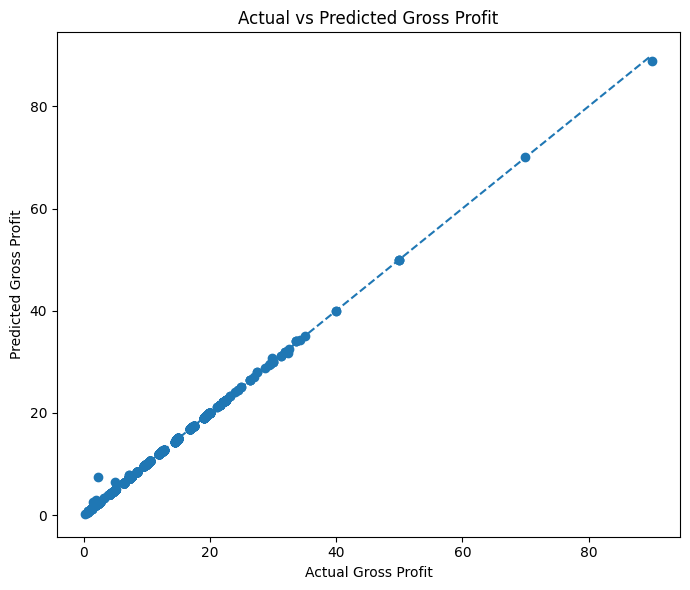

In [930]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Gross Profit")
plt.ylabel("Predicted Gross Profit")
plt.title("Actual vs Predicted Gross Profit")

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.tight_layout()
plt.show()

  Feature  Importance
0   Sales     0.92042
2    Cost     0.06707
1   Units     0.01251


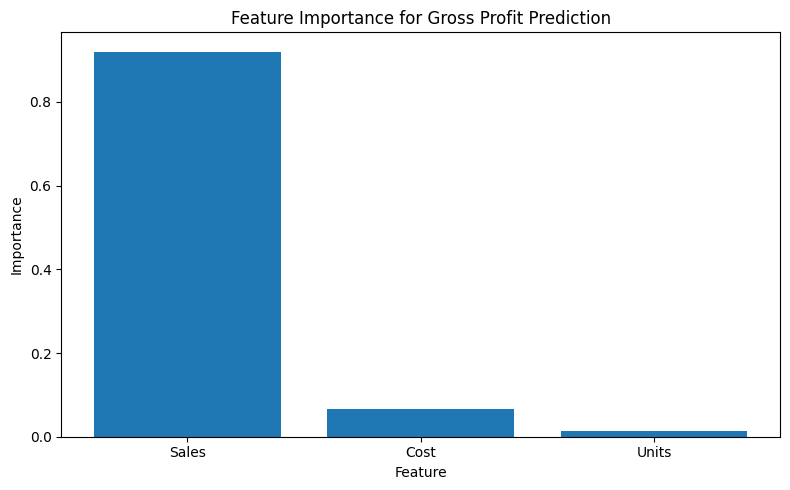

In [931]:
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
)

print(importance)

plt.figure(figsize=(8, 5))
plt.bar(importance["Feature"], importance["Importance"])
plt.title("Feature Importance for Gross Profit Prediction")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [932]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

Mean Absolute Error: 0.007807405590988188
R² Score: 0.999528521556322


In [933]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSample data:")
display(df.head())

Dataset shape: (10194, 18)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']

Data types:
Row ID              int64
Order ID           object
Order Date         object
Ship Date          object
Ship Mode          object
Customer ID         int64
Country/Region     object
City               object
State/Province     object
Postal Code        object
Division           object
Region             object
Product ID         object
Product Name       object
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division       

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [934]:
division_data = df.groupby("Division", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum",
    "Order ID": "nunique"
})

division_data = division_data.rename(
    columns={"Order ID": "Total Orders"}
)

division_data["Profit Margin (%)"] = (
    division_data["Gross Profit"] /
    division_data["Sales"].replace(0, float("nan")) * 100
)

print(division_data.sort_values(
    "Gross Profit", ascending=False
).to_string(index=False))

 Division     Sales  Gross Profit     Cost  Units  Total Orders  Profit Margin (%)
Chocolate 131692.90      88824.62 42868.28  37275          8205          67.448298
    Other   9663.25       4333.45  5329.80   1242           304          44.844643
    Sugar    427.48        284.73   142.75    137            40          66.606625


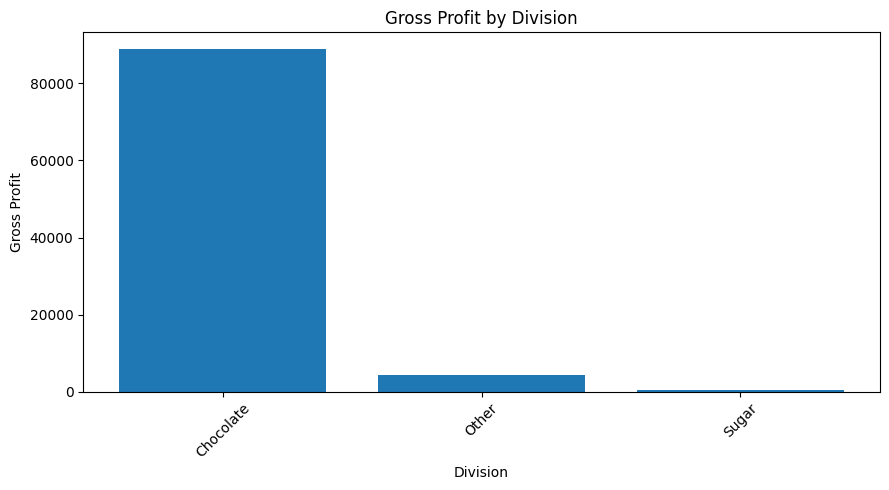

In [935]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(division_data["Division"], division_data["Gross Profit"])
plt.title("Gross Profit by Division")
plt.xlabel("Division")
plt.ylabel("Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Customers by Gross Profit
 Customer ID  Sales  Gross Profit   Cost  Total Orders  Profit Margin (%)
      131807 454.40        256.60 197.80            15          56.470070
      115238 380.50        249.30 131.20            15          65.519054
      122336 352.20        193.44 158.76             3          54.923339
      164756 304.14        166.42 137.72             5          54.718222
      139675 202.00        134.40  67.60            10          66.534653
      151799 197.60        132.52  65.08             6          67.064777
      124163 247.35        127.95 119.40             4          51.728320
      100111 182.41        125.93  56.48             5          69.036785
      164770 232.40        122.50 109.90             2          52.710843
      119508 177.14        122.34  54.80            10          69.064017


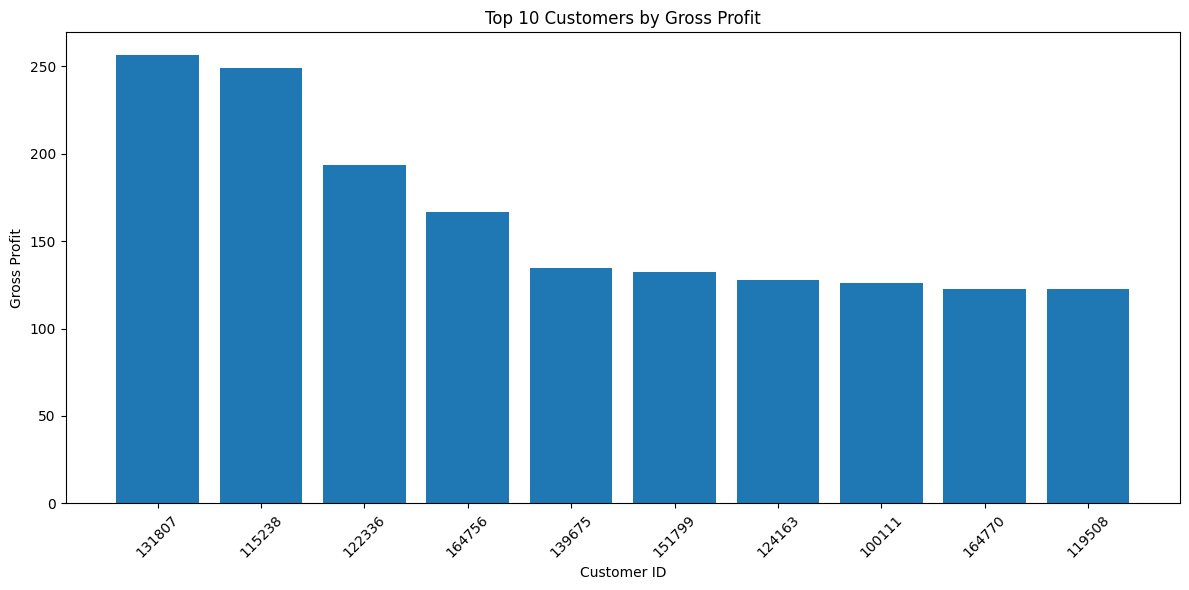

In [936]:
import matplotlib.pyplot as plt

customer_data = df.groupby("Customer ID", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Order ID": "nunique"
})

customer_data = customer_data.rename(
    columns={"Order ID": "Total Orders"}
)

customer_data["Profit Margin (%)"] = (
    customer_data["Gross Profit"] /
    customer_data["Sales"].replace(0, float("nan")) * 100
)

top_customers = customer_data.nlargest(10, "Gross Profit")

print("Top 10 Customers by Gross Profit")
print(top_customers.to_string(index=False))

plt.figure(figsize=(12, 6))
plt.bar(
    top_customers["Customer ID"].astype(str),
    top_customers["Gross Profit"]
)
plt.title("Top 10 Customers by Gross Profit")
plt.xlabel("Customer ID")
plt.ylabel("Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [937]:
product_data = df.groupby(
    ["Product ID", "Product Name"], as_index=False
).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
})

product_data["Profit Margin (%)"] = (
    product_data["Gross Profit"] /
    product_data["Sales"].replace(0, float("nan")) * 100
)

low_margin = product_data[
    product_data["Sales"] > 0
].sort_values("Profit Margin (%)").head(10)

print("10 Lowest-Margin Products")
print(low_margin.to_string(index=False))

10 Lowest-Margin Products
   Product ID                      Product Name    Sales  Gross Profit    Cost  Units  Profit Margin (%)
OTH-KAZ-38000                         Kazookles  1205.75         92.75 1113.00    371           7.692308
SUG-FUN-75000                           Fun Dip    12.00          4.80    7.20      8          40.000000
SUG-NER-92000                             Nerds    15.00          7.00    8.00     10          46.666667
SUG-SWE-91000                         SweeTARTS    61.50         28.70   32.80     41          46.666667
OTH-LIC-15000                Lickable Wallpaper  7860.00       3930.00 3930.00    393          50.000000
OTH-GUM-21000                         Wonka Gum   597.50        310.70  286.80    478          52.000000
OTH-FIZ-56000              Fizzy Lifting Drinks    78.75         47.25   31.50     21          60.000000
SUG-LAF-25000                       Laffy Taffy    53.73         33.48   20.25     27          62.311558
CHO-MIL-31000        Wonka Ba

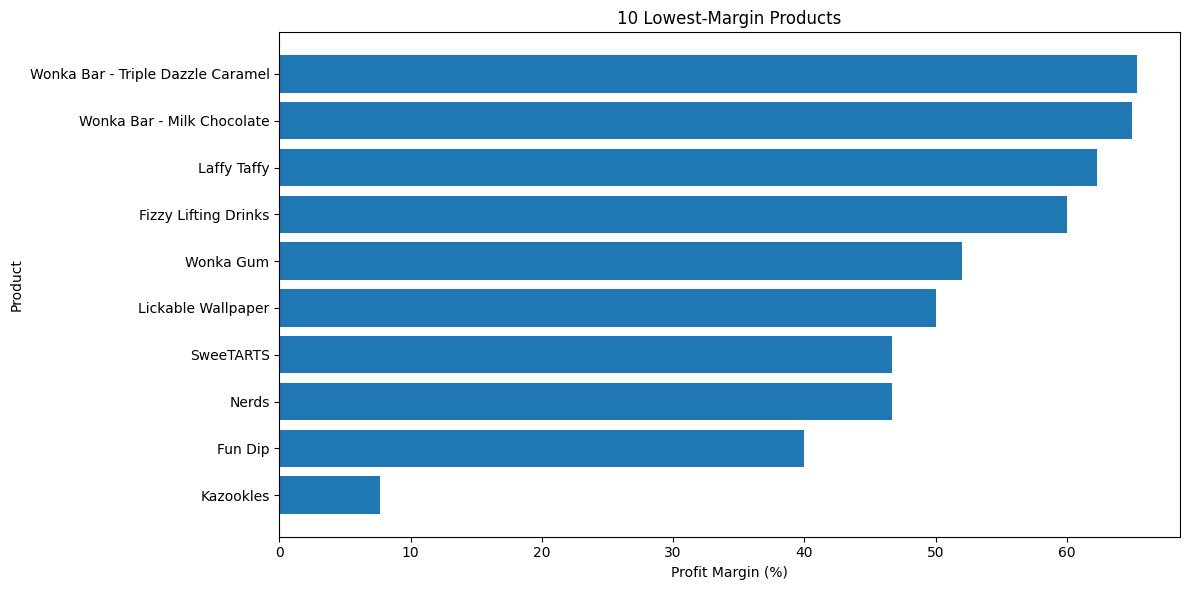

In [938]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.barh(
    low_margin["Product Name"],
    low_margin["Profit Margin (%)"]
)
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product")
plt.title("10 Lowest-Margin Products")
plt.tight_layout()
plt.show()

In [939]:
total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_cost = df["Cost"].sum()
total_units = df["Units"].sum()
total_orders = df["Order ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

print("Total Sales:", round(total_sales, 2))
print("Total Gross Profit:", round(total_profit, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Units Sold:", total_units)
print("Total Orders:", total_orders)
print("Overall Profit Margin (%):", round(profit_margin, 2))

Total Sales: 141783.63
Total Gross Profit: 93442.8
Total Cost: 48340.83
Total Units Sold: 38654
Total Orders: 8549
Overall Profit Margin (%): 65.91


In [940]:
df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Gross Profit"] = pd.to_numeric(df["Gross Profit"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum"
})

print(monthly_data.head())

     Month    Sales  Gross Profit
0  2024-01  1856.73       1238.37
1  2024-02  1997.29       1305.85
2  2024-03  1613.48       1038.38
3  2024-04  1508.05       1006.77
4  2024-05  2429.01       1557.77


In [941]:
print(monthly_data.columns.tolist())
print(monthly_data.head())

['Month', 'Sales', 'Gross Profit']
     Month    Sales  Gross Profit
0  2024-01  1856.73       1238.37
1  2024-02  1997.29       1305.85
2  2024-03  1613.48       1038.38
3  2024-04  1508.05       1006.77
4  2024-05  2429.01       1557.77


In [942]:
df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Gross Profit"] = pd.to_numeric(df["Gross Profit"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum"
})

print(monthly_data.head())

     Month    Sales  Gross Profit
0  2024-01  1856.73       1238.37
1  2024-02  1997.29       1305.85
2  2024-03  1613.48       1038.38
3  2024-04  1508.05       1006.77
4  2024-05  2429.01       1557.77


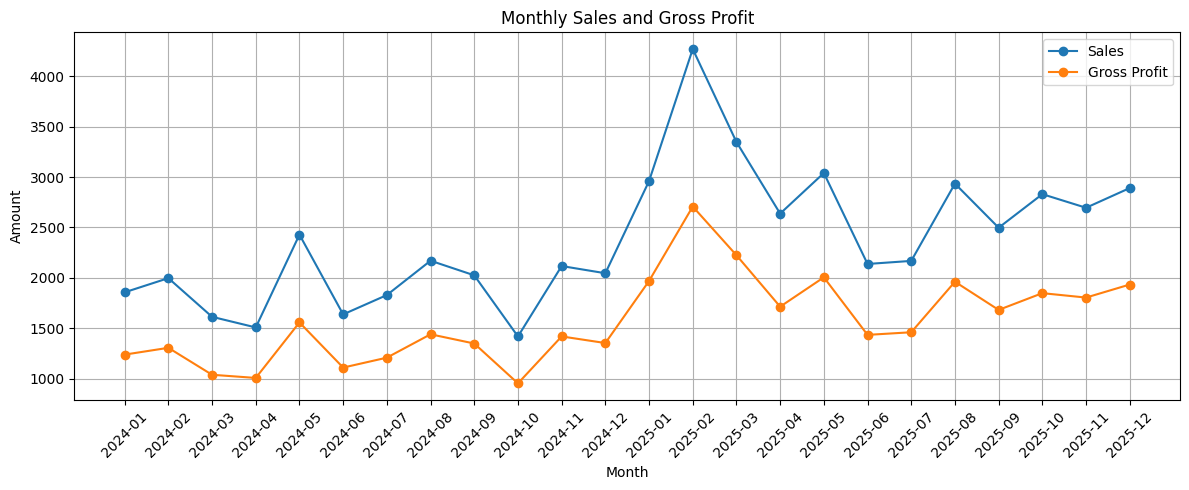

In [943]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.str.strip()

# Convert Order Date into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

# Create monthly data
df = df.dropna(subset=["Order Date"])
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

# Ensure numeric values
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

if "Gross Profit" in df.columns:
    df["Gross Profit"] = pd.to_numeric(
        df["Gross Profit"], errors="coerce"
    )
    monthly_data = df.groupby("Month", as_index=False)[
        ["Sales", "Gross Profit"]
    ].sum()
else:
    monthly_data = df.groupby("Month", as_index=False)[
        ["Sales"]
    ].sum()

# Plot graph
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_data["Month"],
    monthly_data["Sales"],
    marker="o",
    label="Sales"
)

if "Gross Profit" in monthly_data.columns:
    plt.plot(
        monthly_data["Month"],
        monthly_data["Gross Profit"],
        marker="o",
        label="Gross Profit"
    )

plt.xlabel("Month")
plt.ylabel("Amount")
plt.title("Monthly Sales and Gross Profit")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [944]:
print(df.columns.tolist())
print(monthly_data.columns.tolist())
print(monthly_data.head())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Month']
['Month', 'Sales', 'Gross Profit']
     Month    Sales  Gross Profit
0  2024-01  1856.73       1238.37
1  2024-02  1997.29       1305.85
2  2024-03  1613.48       1038.38
3  2024-04  1508.05       1006.77
4  2024-05  2429.01       1557.77


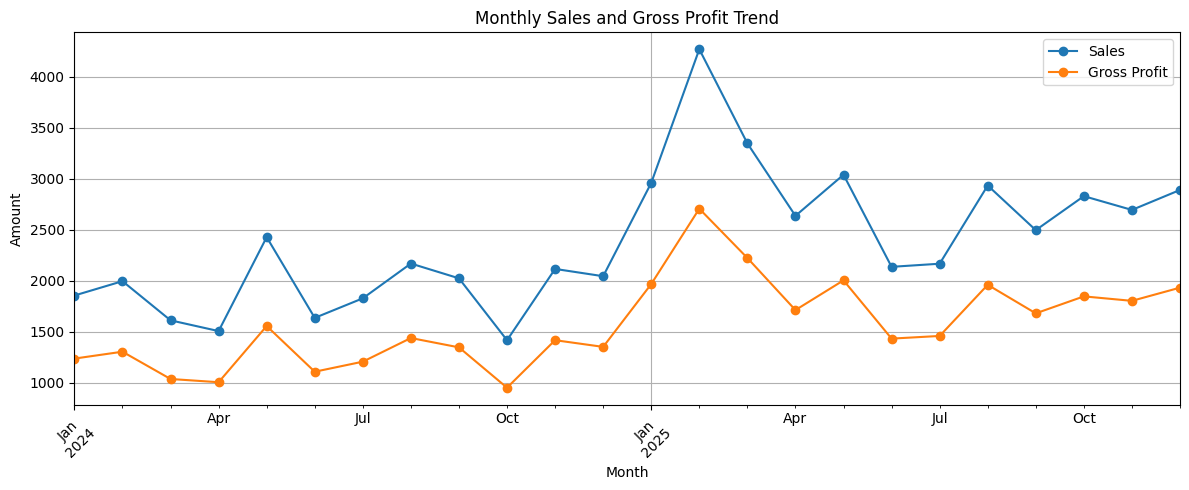

In [945]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M")

monthly_data = temp.groupby("Month")[["Sales", "Gross Profit"]].sum()

ax = monthly_data.plot(figsize=(12, 5), marker="o")

ax.set_title("Monthly Sales and Gross Profit Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [946]:

print("df exists:", "df" in globals())
print("monthly_data exists:", "monthly_data" in globals())


df exists: True
monthly_data exists: True


In [947]:
print(monthly_data.columns.tolist())

['Sales', 'Gross Profit']


     Month    Sales  Gross Profit    Cost
0  2024-01  1856.73       1238.37  618.36
1  2024-02  1997.29       1305.85  691.44
2  2024-03  1613.48       1038.38  575.10
3  2024-04  1508.05       1006.77  501.28
4  2024-05  2429.01       1557.77  871.24


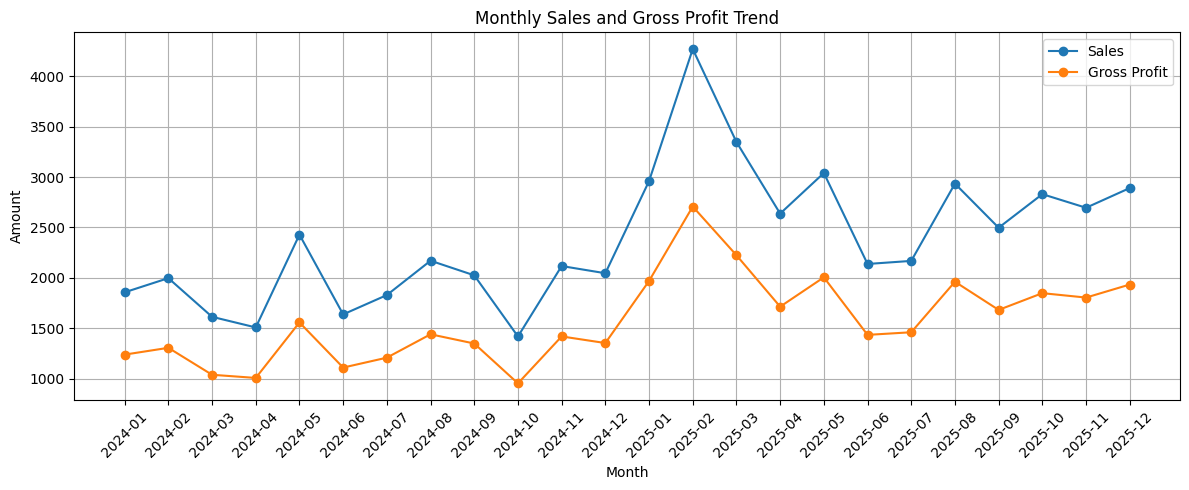

In [948]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly_data["Month"], monthly_data["Sales"], marker="o", label="Sales")
plt.plot(monthly_data["Month"], monthly_data["Gross Profit"], marker="o", label="Gross Profit")

plt.title("Monthly Sales and Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [949]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())


     Month    Sales  Gross Profit    Cost
0  2024-01  1856.73       1238.37  618.36
1  2024-02  1997.29       1305.85  691.44
2  2024-03  1613.48       1038.38  575.10
3  2024-04  1508.05       1006.77  501.28
4  2024-05  2429.01       1557.77  871.24


In [950]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month", observed=True).agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Cost=("Cost", "sum")
).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())


     Month    Sales  Gross_Profit    Cost
0  2024-01  1856.73       1238.37  618.36
1  2024-02  1997.29       1305.85  691.44
2  2024-03  1613.48       1038.38  575.10
3  2024-04  1508.05       1006.77  501.28
4  2024-05  2429.01       1557.77  871.24


In [951]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDate range:")
print("Start:", df["Order Date"].min())
print("End:", df["Order Date"].max())

print("\nSales:", round(df["Sales"].sum(), 2))
print("Cost:", round(df["Cost"].sum(), 2))
print("Gross Profit:", round(df["Gross Profit"].sum(), 2))


Dataset shape: (4130, 19)

Missing values:
0

Date range:
Start: 2024-01-02 00:00:00
End: 2025-12-12 00:00:00

Sales: 57064.92
Cost: 19340.44
Gross Profit: 37724.48


In [952]:

total_sales = df["Sales"].sum()
total_cost = df["Cost"].sum()
total_profit = df["Gross Profit"].sum()
total_orders = df["Order ID"].nunique()
total_products = df["Product Name"].nunique()
total_units = df["Units"].sum()

profit_margin = (
    total_profit / total_sales * 100 if total_sales != 0 else 0
)

print("Total Sales:", round(total_sales, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Gross Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Products:", total_products)
print("Total Units Sold:", total_units)
print("Overall Profit Margin:", round(profit_margin, 2), "%")


Total Sales: 57064.92
Total Cost: 19340.44
Total Gross Profit: 37724.48
Total Orders: 3462
Total Products: 15
Total Units Sold: 15575
Overall Profit Margin: 66.11 %


In [953]:
print("Dataset columns:")
for col in df.columns:
    print(col)

Dataset columns:
Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Country/Region
City
State/Province
Postal Code
Division
Region
Product ID
Product Name
Sales
Units
Gross Profit
Cost
Month


In [954]:

print("Dataset shape:", df.shape)

for col in df.columns:
    if any(word in col.lower() for word in
           ["factory", "latitude", "longitude", "product", "city", "state", "region"]):
        print(f"\n{col}")
        print(df[col].nunique(), "unique values")
        print(df[col].dropna().unique()[:10])


Dataset shape: (4130, 19)

Country/Region
2 unique values
['United States' 'Canada']

City
399 unique values
['Houston' 'Naperville' 'Philadelphia' 'Henderson' 'Athens' 'Los Angeles'
 'Huntsville' 'Laredo' 'Springfield' 'Dover']

State/Province
57 unique values
['Texas' 'Illinois' 'Pennsylvania' 'Kentucky' 'Georgia' 'California'
 'Virginia' 'Delaware' 'Wisconsin' 'Florida']

Region
4 unique values
['Interior' 'Atlantic' 'Gulf' 'Pacific']

Product ID
15 unique values
['CHO-MIL-31000' 'CHO-TRI-54000' 'CHO-NUT-13000' 'CHO-SCR-58000'
 'CHO-FUD-51000' 'OTH-GUM-21000' 'OTH-KAZ-38000' 'OTH-LIC-15000'
 'SUG-NER-92000' 'SUG-SWE-91000']

Product Name
15 unique values
['Wonka Bar - Milk Chocolate' 'Wonka Bar - Triple Dazzle Caramel'
 'Wonka Bar - Nutty Crunch Surprise' 'Wonka Bar -Scrumdiddlyumptious'
 'Wonka Bar - Fudge Mallows' 'Wonka Gum' 'Kazookles' 'Lickable Wallpaper'
 'Nerds' 'SweeTARTS']


In [955]:

# Create product analysis
df.columns = df.columns.str.strip()

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"].replace(0, float("nan"))
) * 100

print("Product analysis created successfully!")
display(product_analysis.head())


Product analysis created successfully!


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
0,Everlasting Gobstopper,100.00,80.00,20.0,80.000000
1,Fizzy Lifting Drinks,15.00,9.00,6.0,60.000000
2,Fun Dip,4.50,1.80,2.7,40.000000
3,Hair Toffee,31.50,24.50,7.0,77.777778
4,Kazookles,393.25,30.25,363.0,7.692308


In [956]:

top_products = product_analysis.sort_values(
    by="Gross Profit",
    ascending=False
)

display(top_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
13,Wonka Bar -Scrumdiddlyumptious,11365.20,7892.50,3472.70,69.444444
12,Wonka Bar - Triple Dazzle Caramel,11058.75,7225.05,3833.70,65.333333
11,Wonka Bar - Nutty Crunch Surprise,9890.66,7056.66,2834.00,71.346705
9,Wonka Bar - Fudge Mallows,10317.60,6878.40,3439.20,66.666667
10,Wonka Bar - Milk Chocolate,10565.75,6859.61,3706.14,64.923077
6,Lickable Wallpaper,3040.00,1520.00,1520.00,50.000000
14,Wonka Gum,253.75,131.95,121.80,52.000000
0,Everlasting Gobstopper,100.00,80.00,20.00,80.000000
4,Kazookles,393.25,30.25,363.00,7.692308
3,Hair Toffee,31.50,24.50,7.00,77.777778


['Month', 'Sales', 'Gross Profit', 'Cost']
     Month    Sales  Gross Profit    Cost
0  2024-01  1856.73       1238.37  618.36
1  2024-02  1997.29       1305.85  691.44
2  2024-03  1613.48       1038.38  575.10
3  2024-04  1508.05       1006.77  501.28
4  2024-05  2429.01       1557.77  871.24


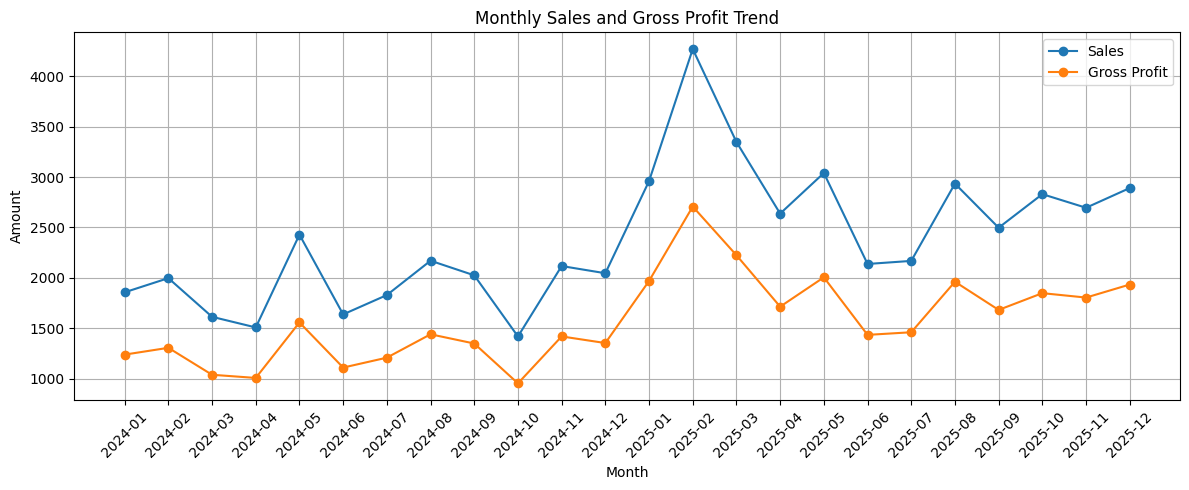

In [957]:

import pandas as pd
import matplotlib.pyplot as plt

df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

for col in ["Sales", "Gross Profit", "Cost"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
})

print(monthly_data.columns.tolist())
print(monthly_data.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly_data["Month"], monthly_data["Sales"],
         marker="o", label="Sales")
plt.plot(monthly_data["Month"], monthly_data["Gross Profit"],
         marker="o", label="Gross Profit")

plt.title("Monthly Sales and Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [958]:
for col in df.columns:
    if any(word in col.lower() for word in
           ["factory", "latitude", "longitude", "product", "location"]):
        print(col, ":", df[col].nunique(), "unique values")

Product ID : 15 unique values
Product Name : 15 unique values


In [959]:
print("Top 10 Products")
display(top_products.head(10))

print("Bottom 10 Products")
display(product_analysis.sort_values(
    by="Gross Profit",
    ascending=True
).head(10))

Top 10 Products


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
13,Wonka Bar -Scrumdiddlyumptious,11365.20,7892.50,3472.70,69.444444
12,Wonka Bar - Triple Dazzle Caramel,11058.75,7225.05,3833.70,65.333333
11,Wonka Bar - Nutty Crunch Surprise,9890.66,7056.66,2834.00,71.346705
9,Wonka Bar - Fudge Mallows,10317.60,6878.40,3439.20,66.666667
10,Wonka Bar - Milk Chocolate,10565.75,6859.61,3706.14,64.923077
6,Lickable Wallpaper,3040.00,1520.00,1520.00,50.000000
14,Wonka Gum,253.75,131.95,121.80,52.000000
0,Everlasting Gobstopper,100.00,80.00,20.00,80.000000
4,Kazookles,393.25,30.25,363.00,7.692308
3,Hair Toffee,31.50,24.50,7.00,77.777778


Bottom 10 Products


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
2,Fun Dip,4.50,1.80,2.7,40.000000
7,Nerds,4.50,2.10,2.4,46.666667
5,Laffy Taffy,7.96,4.96,3.0,62.311558
8,SweeTARTS,16.50,7.70,8.8,46.666667
1,Fizzy Lifting Drinks,15.00,9.00,6.0,60.000000
3,Hair Toffee,31.50,24.50,7.0,77.777778
4,Kazookles,393.25,30.25,363.0,7.692308
0,Everlasting Gobstopper,100.00,80.00,20.0,80.000000
14,Wonka Gum,253.75,131.95,121.8,52.000000
6,Lickable Wallpaper,3040.00,1520.00,1520.0,50.000000


In [960]:

numerical_data = df[
    ["Sales", "Units", "Gross Profit", "Cost"]
]

correlation = numerical_data.corr()

display(correlation)


,Sales,Units,Gross Profit,Cost
Sales,1.000000,0.731633,0.977179,0.959797
Units,0.731633,1.000000,0.818470,0.565406
Gross Profit,0.977179,0.818470,1.000000,0.878269
Cost,0.959797,0.565406,0.878269,1.000000


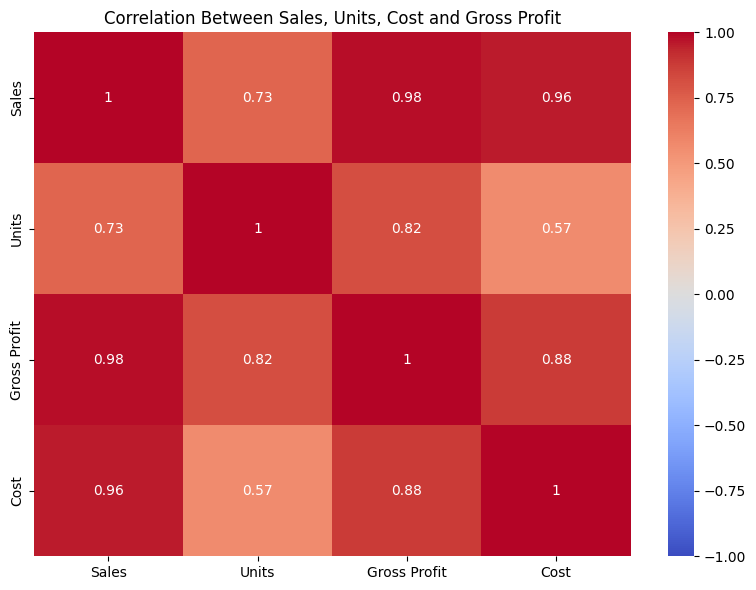

In [961]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Sales, Units, Cost and Gross Profit")
plt.tight_layout()
plt.show()


In [962]:

shipping_analysis = df.groupby("Ship Mode").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Order ID": "nunique"
}).reset_index()

shipping_analysis = shipping_analysis.rename(
    columns={"Order ID": "Number of Orders"}
)

shipping_analysis["Profit Margin (%)"] = (
    shipping_analysis["Gross Profit"] /
    shipping_analysis["Sales"]
) * 100

display(shipping_analysis)


,Ship Mode,Sales,Gross Profit,Cost,Number of Orders,Profit Margin (%)
0,First Class,8724.36,5742.83,2981.53,548,65.825230
1,Same Day,3125.15,2062.07,1063.08,199,65.983073
2,Second Class,11208.84,7379.32,3829.52,667,65.834823
3,Standard Class,34006.57,22540.26,11466.31,2048,66.282074


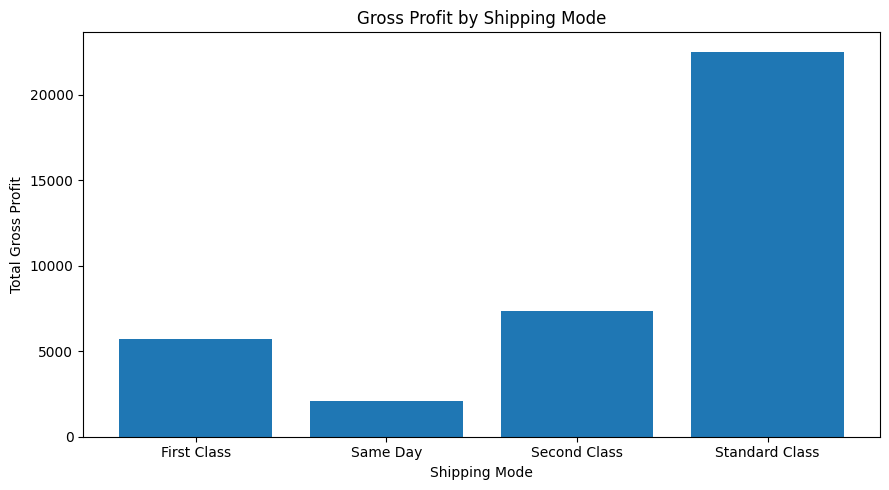

In [963]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    shipping_analysis["Ship Mode"],
    shipping_analysis["Gross Profit"]
)
plt.xlabel("Shipping Mode")
plt.ylabel("Total Gross Profit")
plt.title("Gross Profit by Shipping Mode")
plt.tight_layout()
plt.show()


In [964]:

region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

region_analysis["Profit Margin (%)"] = (
    region_analysis["Gross Profit"] /
    region_analysis["Sales"]
) * 100

region_analysis = region_analysis.sort_values(
    by="Gross Profit", ascending=False
)

display(region_analysis)


,Region,Sales,Gross Profit,Cost,Profit Margin (%)
3,Pacific,18597.20,12287.72,6309.48,66.072957
0,Atlantic,16257.55,10660.59,5596.96,65.573164
2,Interior,13791.88,9167.08,4624.80,66.467226
1,Gulf,8418.29,5609.09,2809.20,66.629802


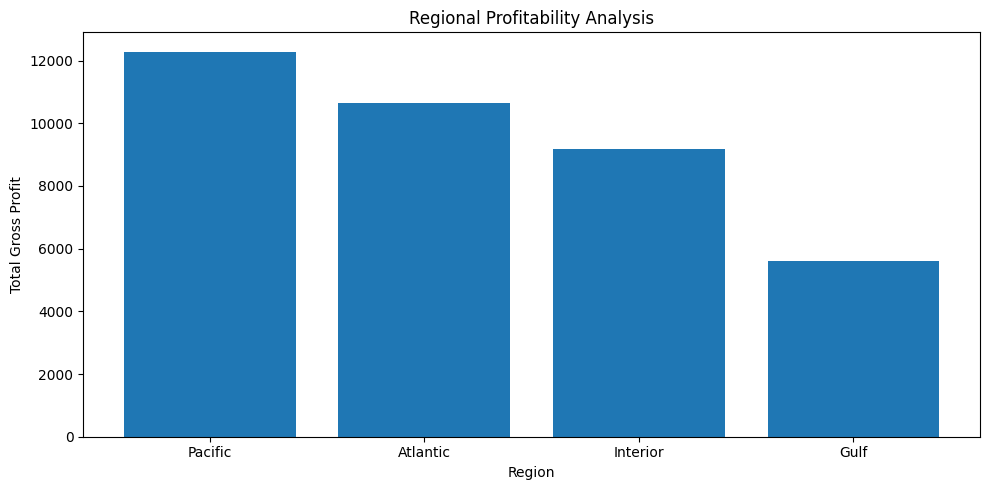

In [965]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(region_analysis["Region"], region_analysis["Gross Profit"])
plt.xlabel("Region")
plt.ylabel("Total Gross Profit")
plt.title("Regional Profitability Analysis")
plt.tight_layout()
plt.show()


In [966]:

df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)

df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Sales"].sum().reset_index()

display(monthly_sales)


,Month,Sales
0,2024-01,1856.73
1,2024-02,1997.29
2,2024-03,1613.48
3,2024-04,1508.05
4,2024-05,2429.01
5,2024-06,1637.55
6,2024-07,1829.38
7,2024-08,2170.22
8,2024-09,2025.31
9,2024-10,1418.45


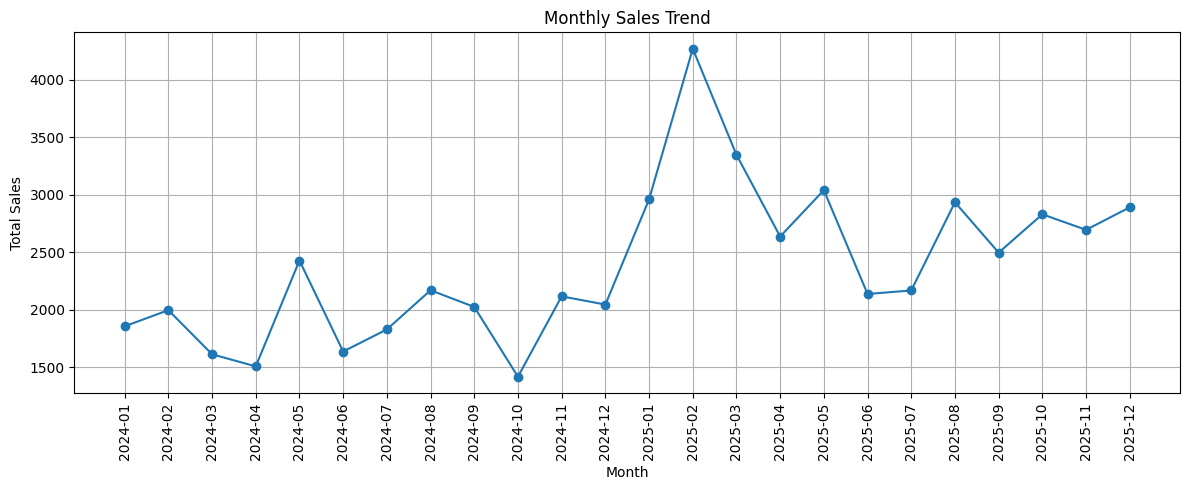

In [967]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month"], monthly_sales["Sales"], marker="o")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


In [968]:

# Create division analysis
df.columns = df.columns.str.strip()

division_analysis = df.groupby("Division", as_index=False).agg({
    "Gross Profit": "sum"
})

display(division_analysis)


,Division,Gross Profit
0,Chocolate,35912.22
1,Other,1682.20
2,Sugar,130.06


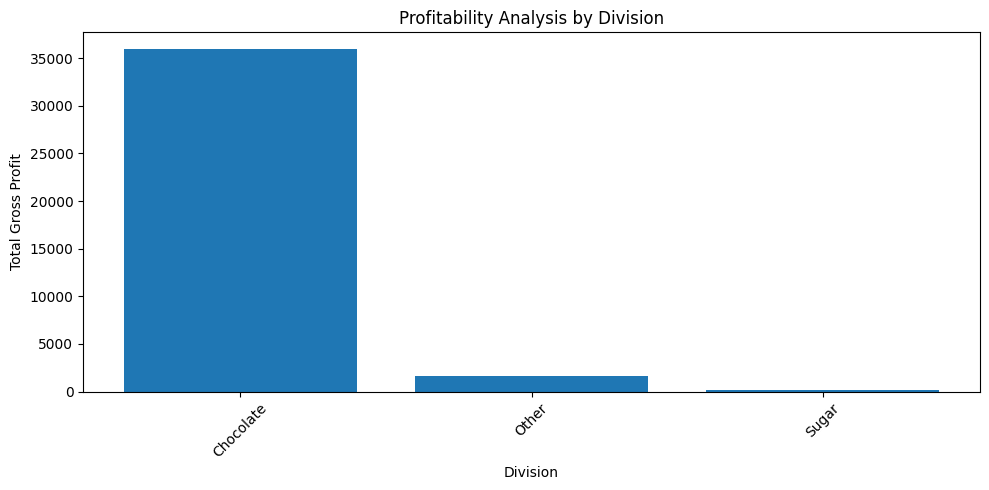

In [969]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(
    division_analysis["Division"],
    division_analysis["Gross Profit"]
)
plt.xlabel("Division")
plt.ylabel("Total Gross Profit")
plt.title("Profitability Analysis by Division")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [970]:

division_analysis = df.groupby("Division").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

division_analysis["Profit Margin (%)"] = (
    division_analysis["Gross Profit"] /
    division_analysis["Sales"]
) * 100

division_analysis = division_analysis.sort_values(
    by="Gross Profit", ascending=False
)

display(division_analysis)


,Division,Sales,Gross Profit,Cost,Profit Margin (%)
0,Chocolate,53197.96,35912.22,17285.74,67.506762
1,Other,3687.00,1682.20,2004.80,45.625170
2,Sugar,179.96,130.06,49.90,72.271616


In [971]:

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] / product_analysis["Sales"]
) * 100

print("Product analysis created successfully!")
display(product_analysis.head())


Product analysis created successfully!


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
0,Everlasting Gobstopper,100.00,80.00,20.0,80.000000
1,Fizzy Lifting Drinks,15.00,9.00,6.0,60.000000
2,Fun Dip,4.50,1.80,2.7,40.000000
3,Hair Toffee,31.50,24.50,7.0,77.777778
4,Kazookles,393.25,30.25,363.0,7.692308


In [972]:

product_margin = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_margin["Profit Margin (%)"] = (
    product_margin["Gross Profit"] / product_margin["Sales"]
) * 100

product_margin = product_margin.sort_values(
    by="Profit Margin (%)", ascending=True
)

product_margin.head(10)


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
4,Kazookles,393.25,30.25,363.00,7.692308
2,Fun Dip,4.50,1.80,2.70,40.000000
7,Nerds,4.50,2.10,2.40,46.666667
8,SweeTARTS,16.50,7.70,8.80,46.666667
6,Lickable Wallpaper,3040.00,1520.00,1520.00,50.000000
14,Wonka Gum,253.75,131.95,121.80,52.000000
1,Fizzy Lifting Drinks,15.00,9.00,6.00,60.000000
5,Laffy Taffy,7.96,4.96,3.00,62.311558
10,Wonka Bar - Milk Chocolate,10565.75,6859.61,3706.14,64.923077
12,Wonka Bar - Triple Dazzle Caramel,11058.75,7225.05,3833.70,65.333333


In [973]:

top_products = df.groupby("Product Name")["Gross Profit"].sum().sort_values(ascending=False).reset_index()

top_products.head(10)


,Product Name,Gross Profit
0,Wonka Bar -Scrumdiddlyumptious,7892.50
1,Wonka Bar - Triple Dazzle Caramel,7225.05
2,Wonka Bar - Nutty Crunch Surprise,7056.66
3,Wonka Bar - Fudge Mallows,6878.40
4,Wonka Bar - Milk Chocolate,6859.61
5,Lickable Wallpaper,1520.00
6,Wonka Gum,131.95
7,Everlasting Gobstopper,80.00
8,Kazookles,30.25
9,Hair Toffee,24.50


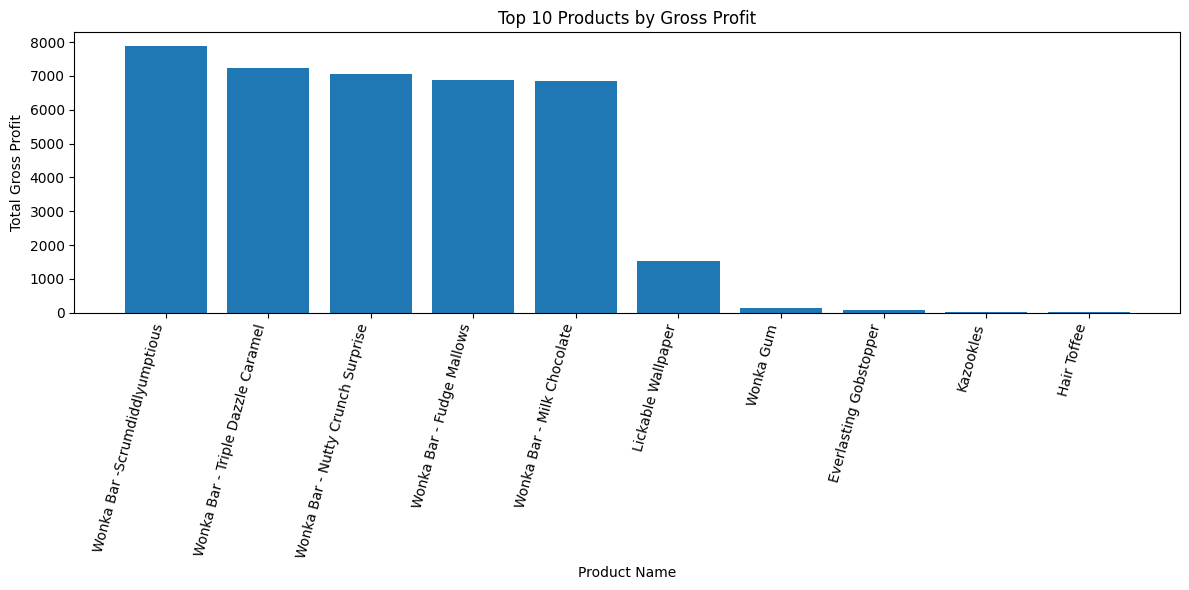

In [974]:

import matplotlib.pyplot as plt

top10 = top_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10["Product Name"], top10["Gross Profit"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Total Gross Profit")
plt.title("Top 10 Products by Gross Profit")
plt.tight_layout()
plt.show()


In [975]:

region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
}).reset_index()

region_analysis["Profit Margin (%)"] = (
    region_analysis["Gross Profit"] /
    region_analysis["Sales"]
) * 100

display(region_analysis)


,Region,Sales,Gross Profit,Cost,Units,Profit Margin (%)
0,Atlantic,16257.55,10660.59,5596.96,4400,65.573164
1,Gulf,8418.29,5609.09,2809.20,2386,66.629802
2,Interior,13791.88,9167.08,4624.80,3792,66.467226
3,Pacific,18597.20,12287.72,6309.48,4997,66.072957


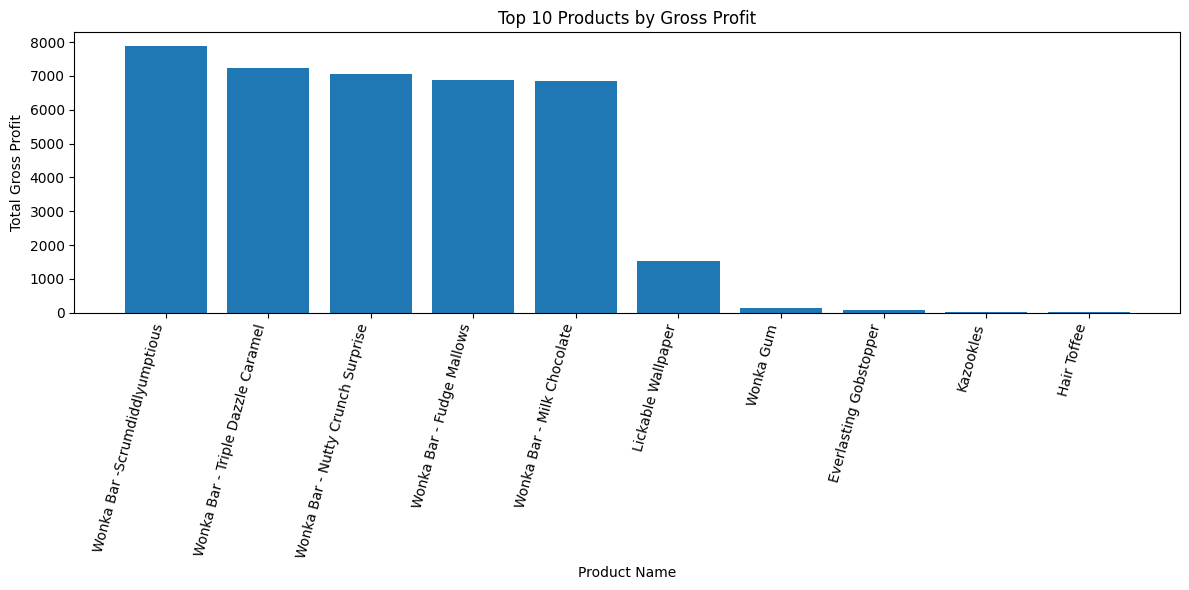

In [976]:

import matplotlib.pyplot as plt

top10 = top_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10["Product Name"], top10["Gross Profit"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Total Gross Profit")
plt.title("Top 10 Products by Gross Profit")
plt.tight_layout()
plt.show()


In [977]:

low_margin_products = product_analysis.sort_values(
    by="Profit Margin (%)",
    ascending=True
)

display(low_margin_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
4,Kazookles,393.25,30.25,363.00,7.692308
2,Fun Dip,4.50,1.80,2.70,40.000000
7,Nerds,4.50,2.10,2.40,46.666667
8,SweeTARTS,16.50,7.70,8.80,46.666667
6,Lickable Wallpaper,3040.00,1520.00,1520.00,50.000000
14,Wonka Gum,253.75,131.95,121.80,52.000000
1,Fizzy Lifting Drinks,15.00,9.00,6.00,60.000000
5,Laffy Taffy,7.96,4.96,3.00,62.311558
10,Wonka Bar - Milk Chocolate,10565.75,6859.61,3706.14,64.923077
12,Wonka Bar - Triple Dazzle Caramel,11058.75,7225.05,3833.70,65.333333


In [978]:

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"]
) * 100


In [979]:

low_margin_products = product_analysis.sort_values(
    by="Profit Margin (%)",
    ascending=True
)

display(low_margin_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
4,Kazookles,393.25,30.25,363.00,7.692308
2,Fun Dip,4.50,1.80,2.70,40.000000
7,Nerds,4.50,2.10,2.40,46.666667
8,SweeTARTS,16.50,7.70,8.80,46.666667
6,Lickable Wallpaper,3040.00,1520.00,1520.00,50.000000
14,Wonka Gum,253.75,131.95,121.80,52.000000
1,Fizzy Lifting Drinks,15.00,9.00,6.00,60.000000
5,Laffy Taffy,7.96,4.96,3.00,62.311558
10,Wonka Bar - Milk Chocolate,10565.75,6859.61,3706.14,64.923077
12,Wonka Bar - Triple Dazzle Caramel,11058.75,7225.05,3833.70,65.333333


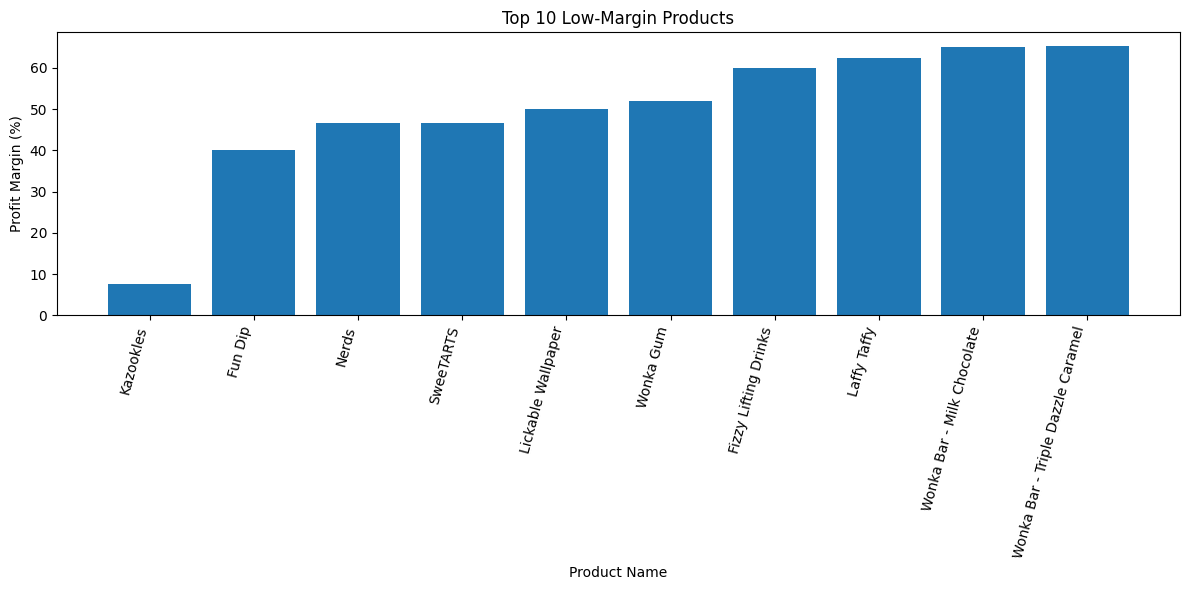

In [980]:

import matplotlib.pyplot as plt

low10 = low_margin_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(low10["Product Name"], low10["Profit Margin (%)"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Profit Margin (%)")
plt.title("Top 10 Low-Margin Products")
plt.tight_layout()
plt.show()


In [981]:

top_products = product_analysis.sort_values(
    by="Gross Profit",
    ascending=False
)

display(top_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
13,Wonka Bar -Scrumdiddlyumptious,11365.20,7892.50,3472.70,69.444444
12,Wonka Bar - Triple Dazzle Caramel,11058.75,7225.05,3833.70,65.333333
11,Wonka Bar - Nutty Crunch Surprise,9890.66,7056.66,2834.00,71.346705
9,Wonka Bar - Fudge Mallows,10317.60,6878.40,3439.20,66.666667
10,Wonka Bar - Milk Chocolate,10565.75,6859.61,3706.14,64.923077
6,Lickable Wallpaper,3040.00,1520.00,1520.00,50.000000
14,Wonka Gum,253.75,131.95,121.80,52.000000
0,Everlasting Gobstopper,100.00,80.00,20.00,80.000000
4,Kazookles,393.25,30.25,363.00,7.692308
3,Hair Toffee,31.50,24.50,7.00,77.777778


In [982]:

import pandas as pd

df["Profit Margin (%)"] = (
    df["Gross Profit"] / df["Sales"]
) * 100

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"]
) * 100

print(product_analysis.head(10))


                Product Name     Sales  Gross Profit    Cost  Units  \
0     Everlasting Gobstopper    100.00         80.00    20.0     10   
1       Fizzy Lifting Drinks     15.00          9.00     6.0      4   
2                    Fun Dip      4.50          1.80     2.7      3   
3                Hair Toffee     31.50         24.50     7.0      7   
4                  Kazookles    393.25         30.25   363.0    121   
5                Laffy Taffy      7.96          4.96     3.0      4   
6         Lickable Wallpaper   3040.00       1520.00  1520.0    152   
7                      Nerds      4.50          2.10     2.4      3   
8                  SweeTARTS     16.50          7.70     8.8     11   
9  Wonka Bar - Fudge Mallows  10317.60       6878.40  3439.2   2866   

   Profit Margin (%)  
0          80.000000  
1          60.000000  
2          40.000000  
3          77.777778  
4           7.692308  
5          62.311558  
6          50.000000  
7          46.666667  
8          

In [983]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [984]:
df.describe()

,Row ID,Order Date,Customer ID,Sales,Units,Gross Profit,Cost,Profit Margin (%)
count,4130.000000,4130,4130.000000,4130.000000,4130.000000,4130.000000,4130.000000,4130.000000
mean,5088.483535,2025-01-25 22:38:45.617433600,134580.606538,13.817172,3.771186,9.134257,4.682915,66.694011
min,1.000000,2024-01-02 00:00:00,100006.000000,1.250000,1.000000,0.250000,0.600000,7.692308
25%,2524.250000,2024-08-09 00:00:00,117324.000000,7.200000,2.000000,4.980000,2.400000,65.333333
50%,5132.500000,2025-02-11 00:00:00,133242.000000,10.800000,3.000000,7.470000,3.600000,66.666667
75%,7783.750000,2025-07-12 00:00:00,152257.500000,18.000000,5.000000,12.250000,5.700000,69.444444
max,9961.000000,2025-12-12 00:00:00,169971.000000,200.000000,14.000000,100.000000,100.000000,80.000000
std,2967.744182,NaN,20295.192380,11.187248,2.192414,6.567177,4.969739,6.161468


In [985]:
display(df.head(10))

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Month,Profit Margin (%)
0,1,US-2021-103800-CHO-MIL-31000,2024-03-01,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,2024-03,64.923077
1,2,US-2021-112326-CHO-TRI-54000,2024-04-01,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,2024-04,65.333333
2,3,US-2021-112326-CHO-NUT-13000,2024-04-01,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,2024-04,71.346705
3,4,US-2021-112326-CHO-SCR-58000,2024-04-01,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,2024-04,69.444444
4,5,US-2021-141817-CHO-TRI-54000,2024-05-01,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,2024-05,65.333333
5,6,US-2021-167199-CHO-SCR-58000,2024-06-01,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,32.40,9,22.50,9.90,2024-06,69.444444
6,7,US-2021-167199-CHO-TRI-54000,2024-06-01,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,2024-06,65.333333
7,8,US-2021-106054-CHO-MIL-31000,2024-06-01,30-06-2026,First Class,106054,United States,Athens,Georgia,30605,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42,2024-06,64.923077
8,9,US-2021-167199-CHO-NUT-13000,2024-06-01,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00,2024-06,71.346705
9,10,US-2021-167199-CHO-MIL-31000,2024-06-01,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,13.00,4,8.44,4.56,2024-06,64.923077


In [986]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (4130, 20)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Month', 'Profit Margin (%)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 4130 entries, 0 to 9960
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Row ID             4130 non-null   int64         
 1   Order ID           4130 non-null   object        
 2   Order Date         4130 non-null   datetime64[ns]
 3   Ship Date          4130 non-null   object        
 4   Ship Mode          4130 non-null   object        
 5   Customer ID        4130 non-null   int64         
 6   Country/Region     4130 non-null   object        
 7   City               4130 non-null   object        
 8   State/Province     

In [987]:

print("Duplicate rows:", df.duplicated().sum())

print("\nSales summary:")
print(df["Sales"].describe())

print("\nGross Profit summary:")
print(df["Gross Profit"].describe())

print("\nCost summary:")
print(df["Cost"].describe())

print("\nInvalid values:")
print("Sales <= 0:", (df["Sales"] <= 0).sum())
print("Cost < 0:", (df["Cost"] < 0).sum())


Duplicate rows: 0

Sales summary:
count    4130.000000
mean       13.817172
std        11.187248
min         1.250000
25%         7.200000
50%        10.800000
75%        18.000000
max       200.000000
Name: Sales, dtype: float64

Gross Profit summary:
count    4130.000000
mean        9.134257
std         6.567177
min         0.250000
25%         4.980000
50%         7.470000
75%        12.250000
max       100.000000
Name: Gross Profit, dtype: float64

Cost summary:
count    4130.000000
mean        4.682915
std         4.969739
min         0.600000
25%         2.400000
50%         3.600000
75%         5.700000
max       100.000000
Name: Cost, dtype: float64

Invalid values:
Sales <= 0: 0
Cost < 0: 0


In [988]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (4130, 20)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Month', 'Profit Margin (%)']

Missing values:
Row ID               0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
Customer ID          0
Country/Region       0
City                 0
State/Province       0
Postal Code          0
Division             0
Region               0
Product ID           0
Product Name         0
Sales                0
Units                0
Gross Profit         0
Cost                 0
Month                0
Profit Margin (%)    0
dtype: int64

Data types:
Row ID                        int64
Order ID                     object
Order Date           datetime64[ns]
Ship Date                    object
Ship Mode                    object
Customer ID    